> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M21-CD - Javier Bueno Sanchez

## El algoritmo KNN y métricas de clasificación 

El objetivo de esta actividad es realizar un análisis de clasificación KNN que permita desarrollar un modelo predictivo basado en distintas métricas aplicadas a una base de datos grande.

### Importación de librerías
En esta sección se importan las bibliotecas necesarias para la lectura de datos, manipulación de información, visualización gráfica
división de datos, escalado de variables y creación de modelos de clasificación utilizando el algoritmo KNN.

In [89]:
import numpy as np
#Biblioteca que permite leer archivos excel y manipular la base de datos como tabla.

In [90]:
import matplotlib.pyplot as plt
##Biblioteca que permite generar gráficos
#Visualizacion de los datos históricos y el ajuste del modelo.

In [91]:
import seaborn as sns
# Visualizacion de datos.

In [92]:
from sklearn.model_selection import train_test_split
# División de datos.

In [93]:
from sklearn.preprocessing import StandardScaler
# Escalado de variables.

In [94]:
from sklearn.neighbors import KNeighborsClassifier
# Importa la herramienta que permite crear un modelo de clasificación utilizando el algoritmo KNN.

In [95]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score,classification_report)
# Importa las herramientas necesarias para evaluar qué tan bien clasifica el modelo KNN.
# accuracy_score calcula que tanto acierta el modelo.¿Cuántas acertó?
# precision_score calcula la precision de las predicciones positivas.
# recall_score sensibilidad del modelo.
# f1_score combinacion de precision y recall.¿Hay un buen equilibrio entre precisión y detección?"
# confusion_matrix construye la matriz de confusion.
# roc_curve genera los datos necesarios para la curva ROC que muestra como cambia el rendimiento del modelo al modificar el umbral.
# roc_auc_score calcula el Área Bajo la Curva (AUC).
# classification_report genera automáticamente un resumen con varias métricas.

In [96]:
import warnings
warnings.filterwarnings("ignore")
# Ignorar advertencias.

In [97]:
import pandas as pd
import sklearn
import matplotlib
import numpy
import seaborn

print("Pandas:", pd.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)
#Verificamos que todas las librerias quedaron instaladas y su version.

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-Learn: 1.7.2
Matplotlib: 3.10.6
Seaborn: 0.13.2


In [98]:
df = pd.read_csv("recursos_humanos.csv")
# Cargamos el archivo

In [99]:
df.head()
# Visualizamos archivo. 

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Análisis exploratorio de los datos

In [100]:
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
# Dimensiones del conjunto de datos.

Filas: 14999
Columnas: 10


In [101]:
df.info()
# Información general del dataset.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [102]:
df.describe()
# Nos muestra valores.

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [103]:
df["salary"].value_counts()
# Verificamos que no existen valores diferentes a los que deben existir.

salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64

In [104]:
df.isnull().sum()
# Valores nulos por variable.

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

## Se verificó la existencia de valores nulos en cada variable del conjunto de datos. No se encontraron registros faltantes, por lo que no fue necesario aplicar técnicas de imputación o eliminación de datos.

In [105]:
df["left"].value_counts()
# Distribución de la variable objetivo.

left
0    11428
1     3571
Name: count, dtype: int64

In [106]:
df["left"].value_counts(normalize=True) * 100
# Distribución porcentual.

left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

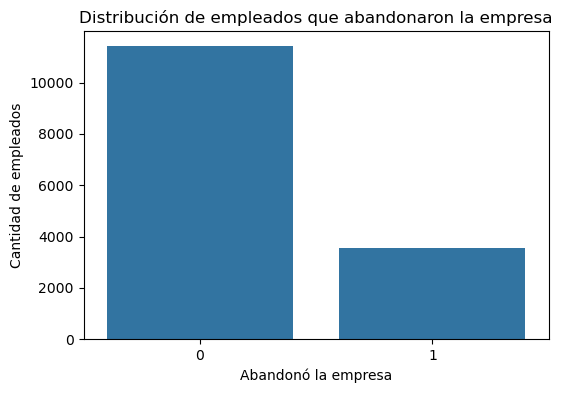

In [107]:
plt.figure(figsize=(6,4))
# Dimensionamos la imagen.
sns.countplot(data=df, x="left")

plt.title("Distribución de empleados que abandonaron la empresa")
plt.xlabel("Abandonó la empresa")
plt.ylabel("Cantidad de empleados")
# Añadimos etiquetas y título al gráfico.

plt.show()
# Visualizamos el gráfico.

## La distribución de la variable objetivo muestra un conjunto de datos desbalanceado, donde aproximadamente el 76 % de los empleados permanecen en la empresa y el 24 % la abandonan. Esto implica que el modelo dispondrá de muchos más ejemplos para aprender las características de los empleados que permanecen, mientras que contará con menos casos correspondientes a quienes abandonan la organización. Debido a este desequilibrio, resulta importante evaluar el modelo no solo mediante la precisión global (Accuracy), sino también utilizando métricas como Precision, Recall y F1 Score, que permiten analizar con mayor detalle su capacidad para identificar correctamente a los empleados que abandonan la empresa, ya que ese es el principal objetivo de este análisis.

## Preparación de los datos

In [108]:
# Variables predictoras (X) y variable objetivo (y)

X = df.drop("left", axis=1)
# Creamos una copia del DataFrame eliminando la columna left.
y = df["left"]


In [109]:
print(X.shape)
print(y.shape)
# Visualizamos X e Y.

(14999, 9)
(14999,)


In [110]:
X = pd.get_dummies(X, drop_first=True)
# Conversión de variables categóricas mediante One-Hot Encoding.
# La categoría eliminada no aporta información adicional, ya que puede inferirse a partir de las restantes variables binarias.
X.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False


## Codificación de variables categóricas.

### Conversión de variables categóricas mediante One-Hot Encoding

In [111]:
X = pd.get_dummies(X, drop_first=True)

X.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False


In [112]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   promotion_last_5years  14999 non-null  int64  
 7   sales_RandD            14999 non-null  bool   
 8   sales_accounting       14999 non-null  bool   
 9   sales_hr               14999 non-null  bool   
 10  sales_management       14999 non-null  bool   
 11  sales_marketing        14999 non-null  bool   
 12  sales_product_mng      14999 non-null  bool   
 13  sales_sales            14999 non-null  bool   
 14  sales_support          14999 non-null  bool   
 15  sa

## División de datos y normalización

In [113]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
# División del conjunto de datos en entrenamiento y prueba.
# test_size = 30% de los datos se guardan para prueba.
# random_state = 42 asegura que el resultado sea reproducible.
# stratify = y mantiene la misma proporción de las clases en los conjuntos de entrenamiento y prueba. 
# De esta forma, ambos representan adecuadamente la distribución original de la base de datos y se evita 
# que una división aleatoria genere muestras poco representativas, lo que podría afectar la evaluación de modelo.

In [114]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)
# Comprobamos funcionamiento del codigo.

(10499, 18)
(4500, 18)
(10499,)
(4500,)


## Normalización de los datos.

In [115]:
scaler = StandardScaler()
# Crea una herramienta cuya única función será normalizar los datos.

X_train = scaler.fit_transform(X_train)
# fit Aprende cómo son los datos. Calcula la media y la desviación estándar.
# transform utiliza esas medias y desviaciones para transformar los datos en una escala comparable.
X_test = scaler.transform(X_test)
# Normalización de las variables.

## Construcción del modelo.
### Construcción del modelo KNN.

In [116]:
knn = KNeighborsClassifier(n_neighbors=5)
# Creación del modelo KNN.

#### Quiero construir un modelo KNN que consulte los 5 vecinos más cercanos para tomar una decisión. Iniciamos con K = 5 porque aun no sabemos cual sera mejor valor.

In [117]:
knn.fit(X_train, y_train)
# Entrenamiento del modelo.

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


## Realizar las predicciones.

In [118]:
y_pred = knn.predict(X_test)
y_pred[:10]
# Recibiremos las primeras 10 predicciones.

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [119]:
resultado = pd.DataFrame({"Real": y_test, "Predicción": y_pred})

resultado.head(10)
# Comparación entre valores reales y predichos.

,Real,Predicción
3946,0,0
10652,0,0
5330,0,0
2669,0,0
10164,0,0
11093,0,0
13125,0,0
10789,0,0
10737,0,0
11409,0,0


In [120]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
# Accuracy (precision) del modelo.

Accuracy: 0.9398


In [121]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Precision: 0.8597
Recall: 0.8926
F1 Score: 0.8759


In [122]:
cm = confusion_matrix(y_test, y_pred)

cm
# Matriz de confusión

array([[3273,  156],
       [ 115,  956]])

## Interpretación de resultados.

### 3273 (True Negatives)

Preguntas que debes responder:

¿Qué ocurrió realmente? El modelo predijo correctamente que estos empleados permanecerían en la empresa y, efectivamente, así ocurrió.
¿Qué predijo el modelo? Predijo que estos empleados no abandonarían la empresa, coincidiendo con el resultado real observado.
¿Qué conclusión objetiva podemos obtener? El modelo muestra una buena capacidad para identificar a los empleados que permanecen en la empresa, contribuyendo al elevado porcentaje de aciertos obtenido.

### 156 (False Positives)

Responde:

¿Qué predijo el modelo? Predijo que estos empleados abandonarían la empresa, pero finalmente permanecieron en ella.
¿Qué ocurrió realmente? Los empleados permanecieron en la empresa a pesar de que el modelo predijo que la abandonarían.
¿Qué implica este error para la empresa? La empresa podría dedicar tiempo y recursos a intervenir con empleados que finalmente no abandonarían la organización.

### 115 (False Negatives)

¿Qué oportunidad perdió la empresa al no identificar correctamente a estos empleados? La empresa perdió la oportunidad de identificar e intervenir sobre empleados que finalmente abandonaron la organización.

### 956 (True Positives)

¿Qué acertó el modelo? El modelo identificó correctamente a los empleados que finalmente abandonaron la empresa.
Permite a Recursos Humanos identificar con anticipación a empleados con riesgo de abandono para diseñar estrategias de retención, sucesión o sustitución cuando sea necesario.
¿Por qué este resultado es útil para RRHH? Crear estrategias de retención, desarrollo, sucesión, sustitución.

## Conclusion.

La matriz de confusión permite conocer no solo el número de aciertos del modelo, sino también el tipo de errores que comete. Esta información facilita identificar oportunidades de mejora y orientar futuras acciones para aumentar la capacidad del modelo de detectar correctamente a los empleados con riesgo de abandonar la empresa.

Los resultados obtenidos invitan también a cuestionar si las variables utilizadas describen completamente el problema. Un modelo solo puede aprender de la información que recibe; por ello, además de evaluar su rendimiento, es importante analizar si los datos recopilados son suficientes o si es necesario incorporar nuevas variables que expliquen mejor el abandono de los empleados.

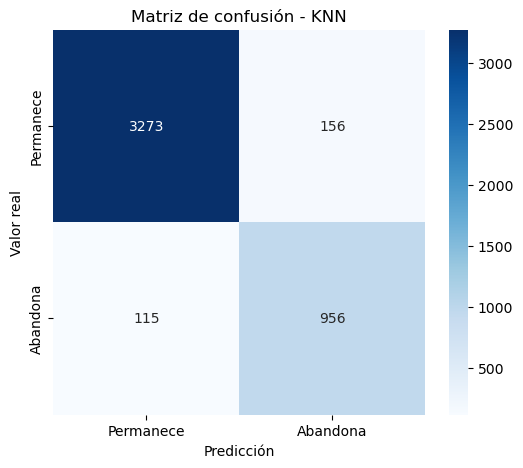

In [123]:
plt.figure(figsize=(6,5))
# Le damos dimensiones al grafico.

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Permanece", "Abandona"], yticklabels=["Permanece", "Abandona"])
# Definimos por medio de una mapa de calor la representacion de los datos.

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - KNN")
# Le ponemos nombre al grafico y a los ejes.

plt.show()

## Curva ROC.

In [124]:
y_proba = knn.predict_proba(X_test)[:, 1]
# predict_proba() muestra el grado de confianza con el que el modelo toma esa decisión.

In [125]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
# frp (false rate positive) "Probabilidad de falso positivo."
# trp (true rate positive) "Probabilidad de verdadero positivo."
# threshold Los distintos niveles de probabilidad que el modelo utiliza para decidir 
# cuando una observación pasa de "permanece" a "abandona".

In [126]:
roc_auc = roc_auc_score(y_test, y_proba)
# El AUC resume el comportamiento global del modelo considerando todos los posibles umbrales de decisión.
# Permite evaluar la capacidad del modelo para distinguir entre ambas clases y proporciona información
# para que la organización seleccione el umbral de decisión más adecuado según las necesidades del negocio.

## Buscamos representar de forma clara el comportamiento del modelo para que la interpretación y la toma de decisiones se apoyen en evidencia, no solo en una métrica aislada o en una visualización atractiva.

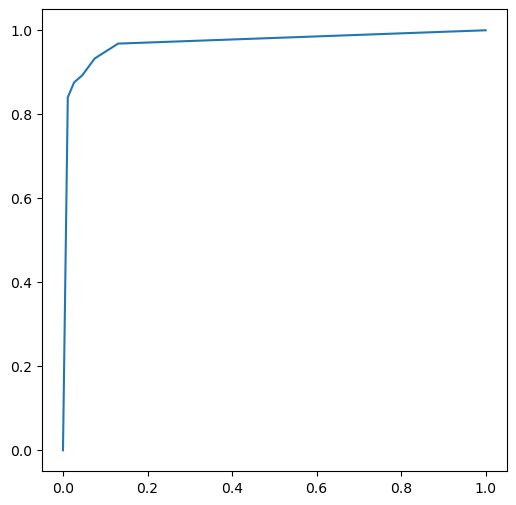

In [127]:
plt.figure(figsize=(6,6))
# Dimensionamos grafico.

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
# Se grafica la curva ROC utilizando la tasa de falsos positivos (FPR)
# y la tasa de verdaderos positivos (TPR).
# Esta visualización permite observar el equilibrio entre detectar correctamente
# los casos positivos y generar falsas alarmas.
# label asigna un nombre descriptivo a la línea representada en la gráfica,
# facilitando su identificación e interpretación por parte del lector.
# La f permite construir mensajes dinámicos utilizando el valor actual de las variables.
# roc_auc Inserta el valor actual de la variable dentro del texto que se mostrará en la gráfica.
# 3f incluye el valor AUC redondeado a tres decimales.(Mostrar tres decimales proporciona la precisión 
# necesaria sin distraer al lector con un nivel de detalle que no aporta valor a la decisión).

### La curva ROC no busca verse bien; busca mostrar qué tan bien separa el modelo las clases cuando cambia el criterio de decisión.

### El objetivo es encontrar el equilibrio que permita obtener la mayor cantidad posible de aciertos, minimizando al mismo tiempo los errores que el modelo genera al tomar sus decisiones.

## Conclusion.

La curva ROC muestra que el modelo posee una buena capacidad para identificar empleados con riesgo de abandono antes de que este ocurra, manteniendo un equilibrio favorable entre la detección de casos positivos y la generación de falsas alarmas. Esta información permite a la organización definir el criterio de actuación más adecuado y priorizar intervenciones preventivas según las necesidades del negocio.

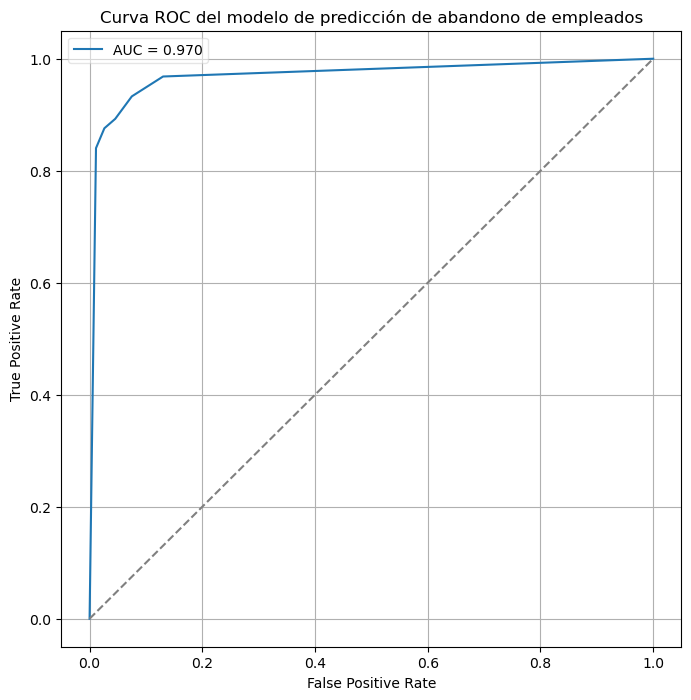

In [128]:
plt.figure(figsize=(8,8))
# Dimensionamos grafico.

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
# Se grafica la curva ROC utilizando la tasa de falsos positivos (FPR)
# y la tasa de verdaderos positivos (TPR).
# Esta visualización permite observar el equilibrio entre detectar correctamente
# los casos positivos y generar falsas alarmas.
# label asigna un nombre descriptivo a la línea representada en la gráfica,
# facilitando su identificación e interpretación por parte del lector.
# La f permite construir mensajes dinámicos utilizando el valor actual de las variables.
# roc_auc Inserta el valor actual de la variable dentro del texto que se mostrará en la gráfica.
# 3f incluye el valor AUC redondeado a tres decimales.(Mostrar tres decimales proporciona la precisión 
# necesaria sin distraer al lector con un nivel de detalle que no aporta valor a la decisión).

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
# Establecemos una referencia común para comparar objetivamente el rendimiento del modelo.

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# Nombramos ambos ejes para que el lector identifique rápidamente qué representa
# cada medida y pueda interpretar la gráfica sin generar confusiones.

plt.title("Curva ROC del modelo de predicción de abandono de empleados")
# Incorporamos un título que contextualiza la visualización,
# permitiendo identificar rápidamente el objetivo del análisis
# antes de interpretar el comportamiento del modelo.

plt.legend(loc="upper left", framealpha=0.5)
# Identificamos cada elemento representado en la gráfica,
# facilitando su reconocimiento, lectura y evitando confusiones durante
# la interpretación y comparación de los resultados.

plt.grid()
# Añadimos referencias visuales que permitan al lector concentrarse
# en interpretar la información sin perder tiempo estimando posiciones
# dentro de la gráfica.

plt.show()
# Mostramos la visualización final de la curva ROC,
# integrando los elementos necesarios para interpretar el comportamiento del modelo
# y comunicar el resultado de forma clara al lector.

## Capítulo completado: Evaluación visual del modelo mediante la curva ROC y el AUC.

## El primer aspecto que llama la atención es que la curva ROC alcanza rápidamente la zona superior izquierda de la gráfica, mostrando una elevada capacidad del modelo para diferenciar entre empleados que permanecerán y empleados con riesgo de abandono. Al mismo tiempo, la distancia respecto a la línea de referencia indica que el modelo aporta información predictiva significativamente superior a una clasificación aleatoria.

## Este comportamiento refleja un buen equilibrio entre la detección de casos positivos y el control de falsas alarmas, permitiendo disponer de una base sólida para apoyar la toma de decisiones.

## El valor de AUC obtenido (0.970) confirma que el modelo presenta un excelente desempeño para distinguir entre ambas clases, proporcionando una base sólida para apoyar la toma de decisiones.

## Sin embargo, una buena capacidad predictiva no debe llevarnos a dar por finalizado el análisis. El siguiente paso consiste en preguntarnos si los datos utilizados describen realmente todas las variables que influyen en el abandono de un empleado o si es necesario incorporar un mayor contexto que permita comprender no solo quién podría abandonar la empresa, sino también qu'e podemos hacer para ser mejores.

## Interpretación de la matriz de confusión

## La matriz de confusión permite identificar no solo cuántas predicciones fueron correctas, sino también el tipo de aciertos y errores cometidos por el modelo.

- **3273 True Negatives:** el modelo predijo correctamente que estos empleados permanecerían en la empresa.
- **156 False Positives:** el modelo predijo que estos empleados abandonarían la empresa, pero realmente permanecieron. Esto representa posibles falsas alarmas.
- **115 False Negatives:** el modelo predijo que estos empleados permanecerían, pero realmente abandonaron la empresa. Este grupo es relevante porque representa casos de abandono que no fueron detectados.
- **956 True Positives:** el modelo identificó correctamente empleados que finalmente abandonaron la organización.

## En conjunto, la matriz muestra que el modelo tiene un buen desempeño general, aunque los falsos negativos deben analizarse con especial atención, ya que representan oportunidades perdidas para intervenir antes del abandono.

# Conclusiones finales.

Se desarrolló un modelo de clasificación mediante el algoritmo KNN con el objetivo de predecir qué empleados podrían abandonar la empresa a partir de las variables disponibles en la base de datos.

Tras evaluar distintos valores de K, el modelo obtuvo su mejor desempeño con **K = 5**, alcanzando una precisión (**Accuracy = 0.9398**). Este resultado permitió no solo cuantificar el porcentaje de aciertos, sino también identificar y analizar el tipo de errores que comete el modelo mediante la matriz de confusión.


Para facilitar la interpretación de los resultados se utilizaron dos herramientas visuales: el mapa de calor de la matriz de confusión y la curva ROC. Mientras el mapa de calor permitió identificar la distribución de aciertos y errores, la curva ROC mostró de forma más clara la capacidad del modelo para distinguir entre empleados que permanecerán en la empresa y aquellos con riesgo de abandono. La ubicación de la curva en la zona superior izquierda y un **AUC de 0.970** respaldan el buen desempeño predictivo del modelo.

Finalmente, puede concluirse que el modelo ofrece resultados satisfactorios con la información disponible. Sin embargo, un buen desempeño estadístico no debe marcar el final del análisis. También es necesario cuestionar si las variables utilizadas describen completamente las causas del abandono o si es posible incorporar información de mayor valor que permita comprender no solo **quién** podría abandonar la organización, sino también **por qué** lo haría. Esa comprensión permitirá orientar estrategias de mejora y apoyar una toma de decisiones mejor fundamentada.